In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [9]:
#Load and combine datasets

users = pd.read_csv('users_cleaned_dataset.csv')
fusers = pd.read_csv('fusers_cleaned_dataset.csv')
df = pd.concat([users, fusers])
df

,id,username,name,account_created_at,bio,bio_length,num_posts,followers_count,following_count,username_length,num_digits_username,digit_ratio_username,followers_following_ratio,fake
0,1,braddd,Davide Dellacasa,2007-04-06 10:58:22+00:00,Founder of http://www.screenweek.it & http://w...,151,20370,5470,2385,6,0,0.0,2.29,0
1,2,eKoeS,Simone Economo,2007-04-30 15:08:42+00:00,BSc degree (cum laude) in Computer Engineering...,104,3131,506,381,5,0,0.0,1.33,0
2,3,tacone_,tacone,2007-05-01 11:53:40+00:00,Cogito ergo bestemmio.,22,4024,264,87,7,0,0.0,3.03,0
3,4,alesstar,alesaura,2007-05-15 16:55:16+00:00,"Se la vita ti dà sarde, scapocciale!",36,40586,640,622,8,0,0.0,1.03,0
4,5,PerDiletto,Angelo,2007-05-13 19:52:00+00:00,Je me souviens,14,2016,62,64,10,0,0.0,0.97,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7334,7335,byroamnh,Byron Ma,2014-04-14 15:06:29,"Tech , music and lover. Leading publishing ...",96,107,13,1482,8,0,0.0,0.01,1
7335,7336,northwindsavhc,Barb,2015-05-02 13:09:37,"North Winds Heating & , Inc. has provided prec...",127,2369,40,967,14,0,0.0,0.04,1
7336,7337,Since_Thereoerf,The Space of,2014-05-10 01:54:51,"Stand-Up Philosopher, Author, Writer, , Artist...",87,11,19,447,15,0,0.0,0.04,1
7337,7338,TheSOILSotre,Shop,2015-06-12 15:33:30,We are your #1 choice for all your landscaping...,113,0,9,680,12,0,0.0,0.01,1


In [10]:
# Feature Selection
features = [
    'bio_length', 'num_posts', 'followers_count', 'following_count', 
    'username_length', 'num_digits_username', 'digit_ratio_username', 
    'followers_following_ratio'
]
X = df[features]
y = df['fake']

In [11]:
# handle missing values & scaling
X = X.fillna(0)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [12]:
# Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

In [13]:
# Logistic Regression
lr_model = LogisticRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_preds))
print(classification_report(y_test, lr_preds))

Logistic Regression Accuracy: 0.8736389684813753
              precision    recall  f1-score   support

           0       0.96      0.82      0.88      2049
           1       0.79      0.95      0.86      1441

    accuracy                           0.87      3490
   macro avg       0.87      0.89      0.87      3490
weighted avg       0.89      0.87      0.87      3490



Logistic Regression have around a 87.4% accuracy, which meant it a linear model. Since it performed well, this show that there is a strong linear relationship between features and the target variable. High precision (0.96) for class 0 but lower precision (0.79) for Class 1, meant occasionally wrong result when the model predicts Class 1, but almost always right when predicts Class 0 because data likely have distinct Class 0 signatures. Overall, reliable baseline.

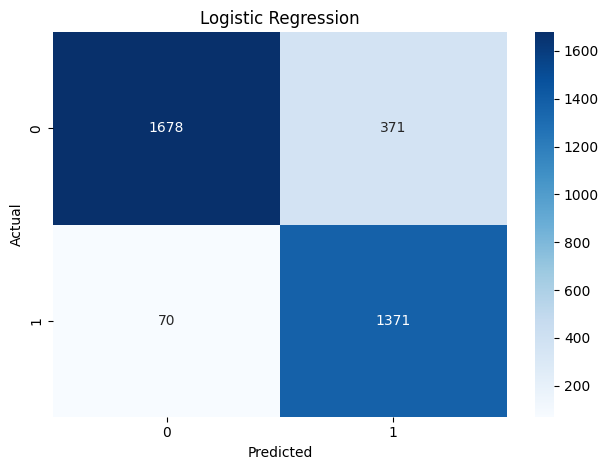

In [14]:
# Logestic Regression Plot
plt.clf()
sns.heatmap(confusion_matrix(y_test, lr_preds), annot=True, fmt='d', cmap='Blues')
plt.title('Logistic Regression')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()

- Only missed 70 fake users or class 1 by incorrectly labeling them as real.
- Mistakenly flagged 371 real users as being fake.
- Correctly identified 1,371 fake users as fake.
- The model correctly identified 1,678 real uers as real.

The model plot is highly sensitive to detecting fake accounts because of 70 false negative compared to 1,371 true positives, which has a very high recall. For that, if an account is fake, there is 95% chance this model will catch it. (fake account correctly caught / total actual fake account)

In [15]:
# Support Vector Classifier (SVC)
svc_model = SVC(kernel='rbf', probability=True)
svc_model.fit(X_train, y_train)
svc_preds = svc_model.predict(X_test)

print("SVC Accuracy:", accuracy_score(y_test, svc_preds))
print(classification_report(y_test, svc_preds))

SVC Accuracy: 0.867621776504298
              precision    recall  f1-score   support

           0       0.95      0.82      0.88      2049
           1       0.79      0.93      0.85      1441

    accuracy                           0.87      3490
   macro avg       0.87      0.88      0.87      3490
weighted avg       0.88      0.87      0.87      3490



Support Vector Classifier (SVC) performance is approximately 86.8% accuracy. The fact that it performed slightly worse than Logistic Regression suggests that adding complex geometric boundaries didn't necessarily help more than simple linear approach. Overall, SVC is telling me that the point of my data is crowded or overlapping each other at the edges of the classes, making it hard for the SVC to find a unique group or perfect gap between them.

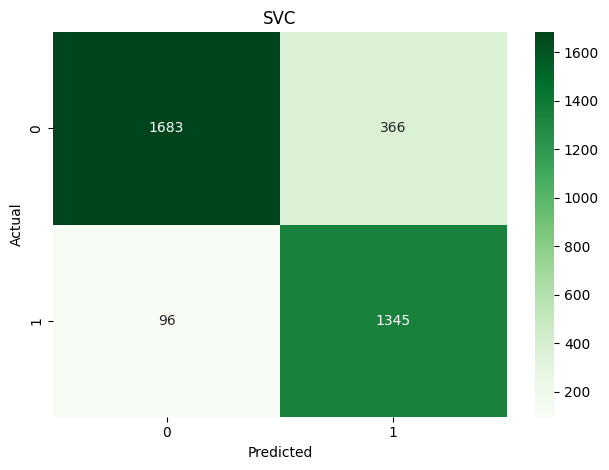

In [16]:
# Support Vector Classifier (SVC) Plot
plt.clf()
sns.heatmap(confusion_matrix(y_test, svc_preds), annot=True, fmt='d', cmap='Greens')
plt.title('SVC')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()

- correctly identified 1,683 real users
- correctly identified 1,345 fake users
- mistakenly flagged 366 real users as fake
- miss 96 fake users

93% (1345/1441), which is close to perfect at catching fake accounts and much stricter than Logisitic Regression model.

In [17]:
#Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_preds))
print(classification_report(y_test, rf_preds))

Random Forest Accuracy: 0.9879656160458453
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2049
           1       0.99      0.98      0.99      1441

    accuracy                           0.99      3490
   macro avg       0.99      0.99      0.99      3490
weighted avg       0.99      0.99      0.99      3490



Random Forest accuracy have 98.8% accuracy which is a massive jump compare to other models. This is nearly a perfect score suggestion that the dataset has certain combination of features are extremly predictive. For that, I have to look back for any overfitting or data leakage that the model can cheat to get the high if an account have been flagged like fake in the first place.

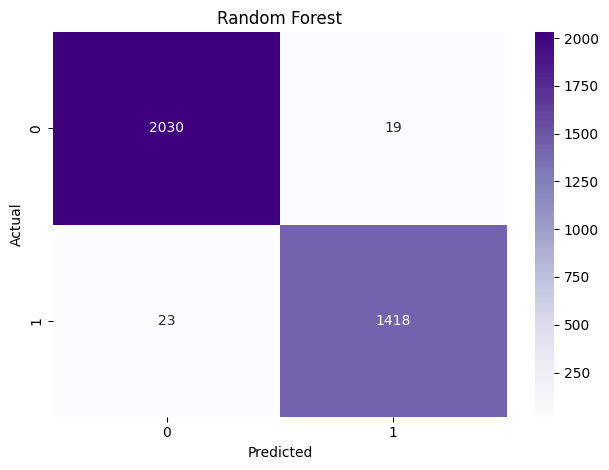

In [18]:
# Random Forest Plot
plt.clf()
sns.heatmap(confusion_matrix(y_test, rf_preds), annot=True, fmt='d', cmap='Purples')
plt.title('Random Forest')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()

- 2030 the model correctly predict real user when the actual value is real (0).
- correctly predicted 1418 fake users when the actual value is fake (1).
- 19 account were predicted as fake, but the actual value was 0.
- 23 accounts were preditced 0, but the actual value was 1.

Both Precision and Recall are very high. The precision of 98.7% (1418/1437) when it predict fake account almost always right. The recall for fake account is 98.4% (1418/1441), succefully capturing nearly all actual fake account instances. The diagonal numbers, 19 and 23, are very small relative to the correct predictions, suggesting the model has found very clear boundaries to separate these two classes.

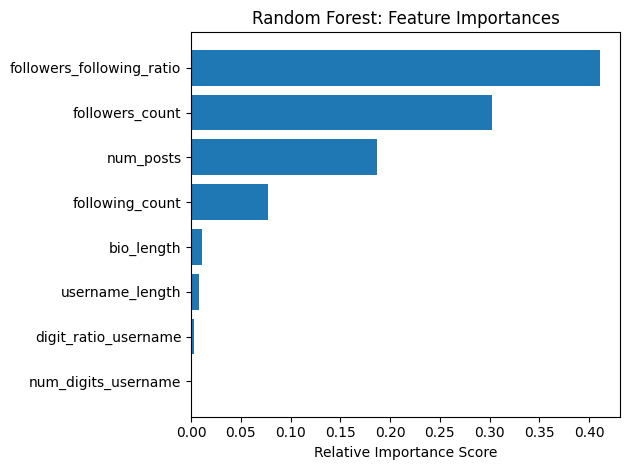

In [19]:
# Features that important for Random Forest
plt.clf()
importances = rf_model.feature_importances_
indices = np.argsort(importances)
plt.title('Random Forest: Feature Importances')
plt.barh(range(len(indices)), importances[indices])
plt.yticks(range(len(indices)), [features[i] for i in indices])
plt.xlabel('Relative Importance Score')
plt.tight_layout()

- Follwers following ratio most influential variable with the score over 0.40. The feature is the strongest red or green flag of impersonation account for the model becuase it present the relationship between how many people an follows vs how many follow it got back.
- Follower count is the second most critical data point with a score of 0.30.
- the number of post (num_post) shown as third in the plot as a signficant role in classfication where the the activity level of how much the account posted.
- The overall bio and username features have low relative importance, nearly to 0. While they might help in finding impersonated account similarity to real account of user information input, the model isn't rely on them heavily to make its final call.

C:\Users\phuon\AppData\Local\Temp\ipykernel_24804\2738439730.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(final_results.keys()), y=list(final_results.values()), palette='magma')


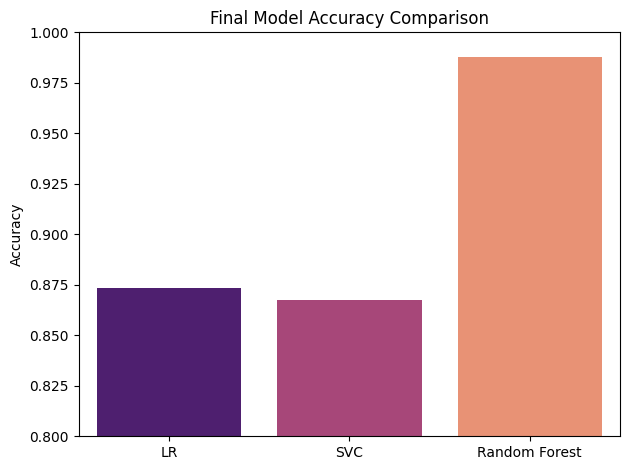

In [20]:
# Accuracy Comparison Of 3 Models
plt.clf()
final_results = {"LR":0.8736389684813753, "SVC":0.867621776504298, "Random Forest":0.9879656160458453}
sns.barplot(x=list(final_results.keys()), y=list(final_results.values()), palette='magma')
plt.title('Final Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.ylim(0.8,1.0)
plt.tight_layout()

The Random Forest have an highest accuracy approximately over 97.5%. Significantly outperform Logistic Regression and SVC. Logistic Regression accuracy score close to 87.5%, which is a respectable score for linear model, but it clearly misses some of the complexities in the data. SVC is slightly lower than Logistic Regression, but still count as lowest of all three model around 86% percent range. Knowing that Random Forest score the highest accuracy suggest that the data is a complex, non-linear relationship. As a result, Random Forest is much better for the relation features. For example, if follower is low and following is high the double the follower count, then it's likely fake account. LR and SVC are looking for straighter lines or boundaries.

<Figure size 640x480 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

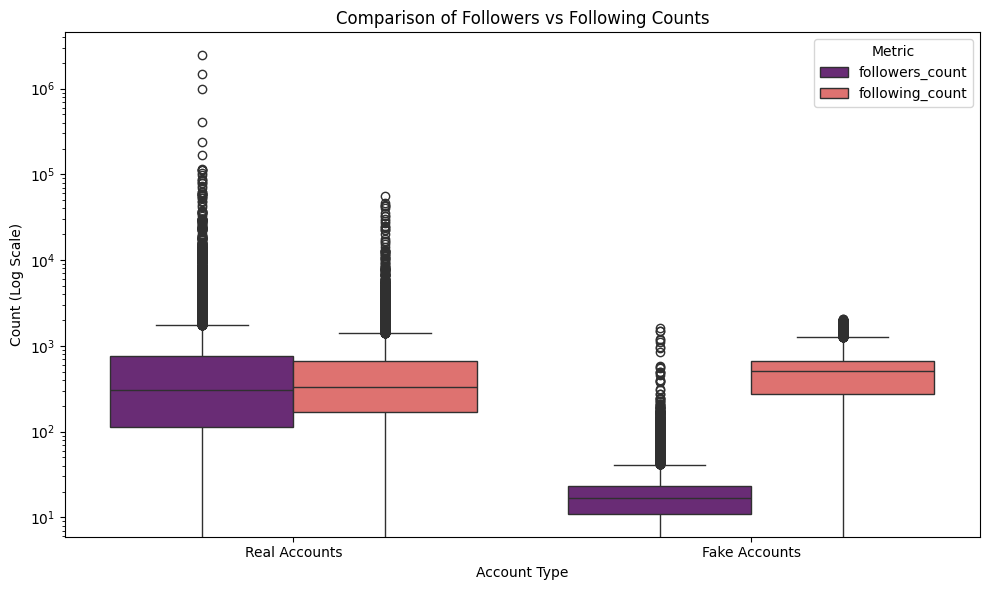

In [21]:
#1. Melt the dataframe using the existing 'fake' column
bp = df.melt(id_vars= 'fake',
                      value_vars=['followers_count', 'following_count'],
                      var_name='Metric',
                      value_name='Count')

# 2. Clear current plot to ensure a fresh start 
plt.clf()
plt.figure(figsize=(10, 6))

# 3. Plot the data
plt.figure(figsize=(10, 6))
sns.boxplot(data=bp, x='fake', y='Count', hue='Metric', palette='magma')

# 4. Rename the 0 and 1 on X-axis
plt.xticks([0, 1], ['Real Accounts', 'Fake Accounts'])

plt.yscale('log')
plt.title('Comparison of Followers vs Following Counts')
plt.ylabel('Count (Log Scale)')
plt.xlabel('Account Type')
plt.tight_layout()

- Distinct Behavior Accounts: Massive disparity in Follower counts between real and fake account. Real accounts have much higher median and a vast range of followers, reaching 10^6, while fake accounts are largely compressed below 10^2.
- Following Bias: Fake accounts tend to have more a big following count than follower counts because the following_count box is signficanly higher than the followers_count box. Real accounts both have a mostly balance box of eachother.
- Ratio gap: gap between purple and orange bar is much wider for fake accounts than real ones, suggest the ratio of these two numbers is a highly consistent differentiator.
- Since there is no overlap in Follower counts for fake and real accounts, the Random Forest model can easily create a split to categorize them. -> followers_following_ratio and followers_count are top two most important features in Random Forest features chart.
- Resilience to Outliers: The box plot shows many outliers (dots). Random Forest is an ensemble of decision tress, which are naturally robust to these extreme values, allowing it to maintain high accuracy where LR or SVC might struggle.
- Clear Decision Boundaries: confusion matrix show only 42 total errors out of nearly 3,500 samples, The distinct, non-overlapping boxes provide the clean data the Random Forest needs to achieve such a high success rate.
